# 🔎 Autonomous Research & Intelligence Agent (PS-02)
Multi-agent pipeline: **Understand → Plan → Search → Read → Credibility → Extract → Cross-verify → Evidence graph → Report**, plus research memory, dynamic expansion, contradiction dashboard, source reliability scores and interactive mode.

**Run top to bottom.** Only input needed: a free **Groq API key** (https://console.groq.com/keys). No dataset needed: the 'data' is live web + arXiv, found by the agent.

**Where to put the API key:** Colab left sidebar → 🔑 *Secrets* → add `GROQ_API_KEY` → enable *Notebook access*. (If absent, Step 2 will prompt you to paste it.)

## Step 1 — Install

In [1]:
!pip -q install groq ddgs trafilatura pypdf networkx matplotlib pandas streamlit

## Step 2 — API key (Groq)

In [2]:
import os
try:
    from google.colab import userdata
    os.environ["GROQ_API_KEY"] = userdata.get("GROQ_API_KEY")          # <- from Colab Secrets
except Exception:
    import getpass
    os.environ["GROQ_API_KEY"] = getpass.getpass("Paste your Groq API key: ")   # <- or paste here
print("Key loaded:", bool(os.environ.get("GROQ_API_KEY")))

Key loaded: True


## Step 3 — The agent system (written to `research_agent.py`, shared with the Streamlit app)

In [3]:
%%writefile research_agent.py
"""
Autonomous Research & Intelligence Agent  (shared by Colab notebook + Streamlit app)

Agents (all coordinated by ResearchAgent = the Orchestrator):
 1 QueryUnderstanding  2 Planner  3 SourceDiscovery  4 DocumentReader
 5 CredibilityAnalyzer 6 FactExtractor  7 CrossVerifier  8 KnowledgeGraph
 9 ReportWriter  10 CitationManager  + Memory, Dynamic Expansion, Interactive mode

LLM: Groq (free API key -> https://console.groq.com/keys). Set env var GROQ_API_KEY.
Search: DuckDuckGo (no key) + arXiv API (no key).
"""
import os, re, json, time, hashlib, datetime, urllib.parse
import xml.etree.ElementTree as ET
from concurrent.futures import ThreadPoolExecutor
from dataclasses import dataclass, field, asdict
from typing import List, Dict, Optional, Callable

import requests
import networkx as nx

import logging
for _n in ("trafilatura", "pypdf", "httpx", "urllib3"):
    logging.getLogger(_n).setLevel(logging.CRITICAL)   # silence harmless parser warnings

UA = {"User-Agent": "Mozilla/5.0 (compatible; ResearchAgent/1.0)"}
DEFAULT_MODEL = os.environ.get("GROQ_MODEL", "openai/gpt-oss-120b")
MEMORY_FILE = os.environ.get("RESEARCH_MEMORY", "research_memory.json")


# ----------------------------------------------------------------------------- helpers
def safe_json(txt: str) -> dict:
    try:
        return json.loads(txt)
    except Exception:
        m = re.search(r"\{.*\}", txt or "", re.S)
        if m:
            try:
                return json.loads(m.group(0))
            except Exception:
                pass
    return {}


def domain_of(url: str) -> str:
    h = urllib.parse.urlparse(url).netloc.lower()
    return h[4:] if h.startswith("www.") else h


def sid_of(url: str) -> str:
    return "S" + hashlib.md5(url.encode()).hexdigest()[:6]


def tokens(text: str) -> set:
    stop = {"the", "a", "an", "of", "to", "in", "and", "or", "is", "are", "for", "on", "with",
            "how", "what", "will", "be", "by", "as", "at", "it", "this", "that", "from", "over", "next"}
    return {w for w in re.findall(r"[a-z0-9]+", (text or "").lower()) if w not in stop and len(w) > 2}


# ----------------------------------------------------------------------------- LLM wrapper
CACHE_FILE = os.environ.get("RESEARCH_LLM_CACHE", "llm_cache.json")


class LLM:
    """Groq wrapper: disk cache (identical prompt = 0 API calls), call counter, smart 429 handling."""

    def __init__(self, api_key: Optional[str] = None, model: str = DEFAULT_MODEL, cache_file: Optional[str] = CACHE_FILE):
        from groq import Groq
        key = api_key or os.environ.get("GROQ_API_KEY")
        if not key:
            raise RuntimeError("GROQ_API_KEY missing. Set it in Colab secrets / env / Streamlit sidebar.")
        self.client = Groq(api_key=key)
        self.model = model
        self.calls, self.hits = 0, 0
        self.cache_file = cache_file
        try:
            self.cache = json.load(open(cache_file)) if cache_file else {}
        except Exception:
            self.cache = {}

    def _save(self):
        if self.cache_file:
            try:
                json.dump(self.cache, open(self.cache_file, "w"))
            except Exception:
                pass

    @staticmethod
    def _wait(err, attempt):
        m = re.search(r"try again in (?:(\d+)m)?([\d.]+)(ms|s)", str(err))
        if m:
            secs = int(m.group(1) or 0) * 60 + float(m.group(2)) / (1000 if m.group(3) == "ms" else 1)
            return min(secs + 1, 70)
        return min(2 ** attempt * 2, 40)

    def chat(self, system: str, user: str, json_mode=False, temperature=0.2, max_tokens=2500, model=None) -> str:
        model = model or self.model
        key = hashlib.sha1(json.dumps([model, system, user, json_mode, max_tokens]).encode()).hexdigest()
        if key in self.cache:
            self.hits += 1
            return self.cache[key]
        last = None
        for attempt in range(6):
            try:
                kw = {"response_format": {"type": "json_object"}} if json_mode else {}
                mt = max_tokens * 3 if "gpt-oss" in model else max_tokens   # reasoning tokens count too
                self.calls += 1
                r = self.client.chat.completions.create(
                    model=model, temperature=temperature, max_tokens=mt,
                    messages=[{"role": "system", "content": system}, {"role": "user", "content": user}], **kw)
                out = r.choices[0].message.content
                if not out:
                    raise RuntimeError("empty completion")
                self.cache[key] = out
                self._save()
                return out
            except Exception as e:
                last = e
                low = str(e).lower()
                if "per day" in low or "tpd" in low or "rpd" in low:     # daily quota: retrying only burns more calls
                    raise RuntimeError(f"Groq DAILY limit reached for {model}. Wait for reset or use another model. ({e})")
                time.sleep(self._wait(e, attempt))
        raise RuntimeError(f"LLM call failed: {last}")

    def json(self, task: str, system: str, user: str, **kw) -> dict:
        txt = self.chat(system + "\nReturn ONLY a valid JSON object.", user, json_mode=True, **kw)
        return safe_json(txt)


# ----------------------------------------------------------------------------- data models
@dataclass
class Source:
    url: str
    title: str = ""
    snippet: str = ""
    origin: str = "web"           # web | news | arxiv
    published: Optional[str] = None
    text: str = ""
    full_text: bool = False
    credibility: float = 0.0
    cred_breakdown: Dict = field(default_factory=dict)
    section: str = ""
    id: str = ""

    def __post_init__(self):
        self.id = self.id or sid_of(self.url)


@dataclass
class Fact:
    id: str
    source_id: str
    text: str
    type: str = "fact"            # fact | statistic | claim
    section: str = ""


@dataclass
class Session:
    query: str
    understanding: Dict = field(default_factory=dict)
    plan: List[Dict] = field(default_factory=list)
    sources: Dict[str, Source] = field(default_factory=dict)
    rejected: List[Source] = field(default_factory=list)
    facts: List[Fact] = field(default_factory=list)
    agreements: List[Dict] = field(default_factory=list)
    contradictions: List[Dict] = field(default_factory=list)
    graph: Optional[nx.DiGraph] = None
    report: str = ""
    sections_md: Dict[str, str] = field(default_factory=dict)
    refs: Dict[str, int] = field(default_factory=dict)
    log: List[str] = field(default_factory=list)


# ----------------------------------------------------------------------------- Agent 3: source discovery
def search_web(q: str, n=6) -> List[Source]:
    try:
        try:
            from ddgs import DDGS
        except ImportError:
            from duckduckgo_search import DDGS
        return [Source(url=r["href"], title=r.get("title", ""), snippet=r.get("body", ""), origin="web")
                for r in DDGS().text(q, max_results=n) if r.get("href")]
    except Exception:
        return []


def search_news(q: str, n=4) -> List[Source]:
    try:
        try:
            from ddgs import DDGS
        except ImportError:
            from duckduckgo_search import DDGS
        return [Source(url=r["url"], title=r.get("title", ""), snippet=r.get("body", ""), origin="news",
                       published=r.get("date")) for r in DDGS().news(q, max_results=n) if r.get("url")]
    except Exception:
        return []


def search_arxiv(q: str, n=4) -> List[Source]:
    try:
        words = list(tokens(q))[:6]
        if not words:
            return []
        r = requests.get("https://export.arxiv.org/api/query", headers=UA, timeout=25,
                         params={"search_query": " AND ".join(f"all:{w}" for w in words),
                                 "max_results": n, "sortBy": "relevance"})
        ns = {"a": "http://www.w3.org/2005/Atom"}
        out = []
        for e in ET.fromstring(r.content).findall("a:entry", ns):
            link = e.find("a:id", ns).text.strip()
            title = " ".join(e.find("a:title", ns).text.split())
            summ = " ".join(e.find("a:summary", ns).text.split())
            pub = e.find("a:published", ns).text[:10]
            out.append(Source(url=link, title=title, snippet=summ[:300], origin="arxiv", published=pub,
                              text=f"{title}. {summ}", full_text=False))
        return out
    except Exception:
        return []


# ----------------------------------------------------------------------------- Agent 4: document reader
def read_url(src: Source, max_chars=6000) -> Source:
    if src.text:                         # e.g. arXiv abstract already present
        src.text = src.text[:max_chars]
        return src
    try:
        r = requests.get(src.url, headers=UA, timeout=20)
        ctype = r.headers.get("content-type", "").lower()
        if "pdf" in ctype or src.url.lower().endswith(".pdf"):
            import io
            from pypdf import PdfReader
            rd = PdfReader(io.BytesIO(r.content))
            txt = " ".join((p.extract_text() or "") for p in rd.pages[:8])
        else:
            import trafilatura
            txt = trafilatura.extract(r.text, include_comments=False, include_tables=False) or ""
            if not src.published:
                try:
                    md = trafilatura.extract_metadata(r.text)
                    if md and md.date:
                        src.published = md.date
                except Exception:
                    pass
        txt = re.sub(r"\s+", " ", txt).strip()
        if len(txt) > 300:
            src.text, src.full_text = txt[:max_chars], True
            return src
    except Exception:
        pass
    src.text = src.snippet            # fall back to the search snippet
    src.full_text = False
    return src


# ----------------------------------------------------------------------------- Agent 5: credibility
GOV = ["nist.gov", "nsa.gov", "cisa.gov", "whitehouse.gov", "europa.eu", "enisa.europa.eu", "ncsc.gov.uk",
       "energy.gov", "nasa.gov", "who.int", "un.org", "oecd.org", "worldbank.org", "imf.org", "bis.org"]
JOURNAL = ["nature.com", "science.org", "ieee.org", "acm.org", "springer.com", "sciencedirect.com", "cell.com",
           "pnas.org", "aps.org", "nejm.org", "thelancet.com", "wiley.com", "arxiv-peer"]
NEWS = ["reuters.com", "ft.com", "bloomberg.com", "apnews.com", "bbc.com", "bbc.co.uk", "nytimes.com", "wsj.com",
        "economist.com", "technologyreview.com", "quantamagazine.org", "wired.com", "arstechnica.com", "theguardian.com"]
INDUSTRY = ["ibm.com", "microsoft.com", "google.com", "mckinsey.com", "gartner.com", "deloitte.com", "bcg.com",
            "accenture.com", "forrester.com", "cloudflare.com", "nvidia.com", "aws.amazon.com", "cisco.com"]
LOWQ = ["medium.com", "substack.com", "blogspot.com", "wordpress.com", "quora.com", "reddit.com", "linkedin.com",
        "facebook.com", "twitter.com", "x.com", "tumblr.com", "pinterest.com", "youtube.com", "tiktok.com"]


def _match(d, lst):
    return any(d == x or d.endswith("." + x) for x in lst)


def score_credibility(src: Source) -> Source:
    """Transparent heuristic: domain authority + peer review + recency + content depth."""
    d = domain_of(src.url)
    peer = False
    if _match(d, GOV):
        base, kind = 95, "government / standards body"
    elif _match(d, JOURNAL):
        base, kind, peer = 92, "peer-reviewed journal / publisher", True
    elif d.endswith((".gov", ".edu", ".int")) or ".ac." in d or d.endswith(".gov.uk"):
        base, kind = 88, "government / academic institution"
    elif d.endswith("arxiv.org"):
        base, kind = 72, "preprint (not peer reviewed)"
    elif _match(d, NEWS):
        base, kind = 82, "established news outlet"
    elif _match(d, INDUSTRY):
        base, kind = 76, "industry / research firm"
    elif d.endswith("wikipedia.org"):
        base, kind = 58, "encyclopedia (secondary)"
    elif _match(d, LOWQ):
        base, kind = 30, "blog / social / user-generated"
    elif d.endswith(".org"):
        base, kind = 58, "organisation (.org)"
    else:
        base, kind = 48, "unknown domain"
    adj = {}
    if src.url.startswith("https"):
        adj["https"] = 2
    year = None
    if src.published:
        m = re.search(r"(19|20)\d{2}", str(src.published))
        year = int(m.group(0)) if m else None
    if year:
        age = datetime.date.today().year - year
        adj["recency"] = 3 if age <= 2 else (0 if age <= 6 else -8)
    if src.full_text:
        adj["full_text_read"] = 3
    elif len(src.text) < 200:
        adj["thin_content"] = -10
    score = max(5, min(99, base + sum(adj.values())))
    src.credibility = float(score)
    src.cred_breakdown = {"domain": d, "category": kind, "base": base, "peer_reviewed": peer, "adjustments": adj}
    return src


# ----------------------------------------------------------------------------- Orchestrator
class ResearchAgent:
    def __init__(self, llm=None, max_sources=16, min_credibility=40, max_contradictions=3,
                 expand_topics=True, fast_model=None, batch_size=3, memory_file=MEMORY_FILE, search_fn=None, news_fn=None, arxiv_fn=None,
                 reader_fn=None, log_fn: Callable[[str], None] = print):
        self.llm = llm or LLM()
        self.max_sources, self.min_cred = max_sources, min_credibility
        self.max_contra, self.expand_topics = max_contradictions, expand_topics
        self.fast_model, self.batch_size = fast_model, max(1, batch_size)   # optional cheap model for extraction only
        self.memory_file = memory_file
        self.search_web = search_fn or search_web
        self.search_news = news_fn or search_news
        self.search_arxiv = arxiv_fn or search_arxiv
        self.reader = reader_fn or read_url
        self._log = log_fn
        self.memory = self._load_memory()
        self.s: Optional[Session] = None

    # ---- logging / memory
    def log(self, msg):
        if self.s:
            self.s.log.append(msg)
        self._log(msg)

    def _load_memory(self):
        try:
            return json.load(open(self.memory_file))
        except Exception:
            return {"investigations": [], "url_cache": {}}

    def _save_memory(self):
        s = self.s
        self.memory["investigations"].append({
            "query": s.query, "date": str(datetime.date.today()),
            "topic": s.understanding.get("main_topic", ""), "n_sources": len(s.sources), "n_facts": len(s.facts)})
        for src in s.sources.values():
            self.memory["url_cache"][src.url] = {
                "title": src.title, "credibility": src.credibility, "published": src.published,
                "facts": [f.text for f in s.facts if f.source_id == src.id][:8]}
        try:
            json.dump(self.memory, open(self.memory_file, "w"), indent=1)
        except Exception:
            pass

    def related_past(self, query):
        qt = tokens(query)
        out = []
        for inv in self.memory.get("investigations", []):
            it = tokens(inv["query"] + " " + inv.get("topic", ""))
            if qt and len(qt & it) / len(qt | it) > 0.25:
                out.append(inv)
        return out

    # ---- main entry
    def run(self, query: str) -> Session:
        self.s = s = Session(query=query)
        c0, h0 = getattr(self.llm, "calls", 0), getattr(self.llm, "hits", 0)
        past = self.related_past(query)
        if past:
            self.log(f"[Memory] {len(past)} related past investigation(s) found; cached URLs will be reused.")
        self.understand(); self.plan()
        self.discover(); self.read_and_score(list(s.sources.values()))
        self.extract_all()
        if self.expand_topics:
            self.expand()
        self.verify()
        self.build_graph()
        self.write_report()
        self._save_memory()
        self.log(f"[Stats] Groq requests this run: {getattr(self.llm, 'calls', 0) - c0} | served from cache: {getattr(self.llm, 'hits', 0) - h0}")
        self.log("[Done] Report generated.")
        return s

    # ---- Agent 1: query understanding
    def understand(self):
        self.log("[1/9] Query Understanding Agent")
        self.s.understanding = self.llm.json(
            "understand",
            "You are a research query analyst. Output keys: main_topic (str), related_topics (list of str), "
            "research_objectives (list of 4-6 str), time_horizon (str or null), question_type (str).",
            self.s.query)

    # ---- Agent 2: planner
    def plan(self):
        self.log("[2/9] Research Planning Agent")
        u = self.s.understanding
        d = self.llm.json(
            "plan",
            "You are a research planner. Create 5-6 report sections that together answer the question. "
            "Output: {\"sections\":[{\"title\":str,\"goal\":str,\"queries\":[2 short web search queries]}]}. "
            "Make queries specific and aimed at diverse source types (academic, government/standards, industry, news).",
            f"Question: {self.s.query}\nUnderstanding: {json.dumps(u)}")
        secs = [x for x in d.get("sections", []) if x.get("title")][:6]
        if not secs:  # fallback
            secs = [{"title": o, "goal": o, "queries": [f"{self.s.query} {o}"]}
                    for o in (u.get("research_objectives") or [self.s.query])[:5]]
        self.s.plan = secs
        for x in secs:
            self.log(f"      - {x['title']}")

    # ---- Agent 3: discovery
    def _search_for(self, queries: List[str], section: str, per_q=5) -> List[Source]:
        found = []
        for i, q in enumerate(queries[:2]):
            found += self.search_web(q, per_q)
            if i == 0:
                found += self.search_arxiv(q, 3)
                found += self.search_news(q, 3)
        for f in found:
            f.section = section
        return found

    def discover(self):
        self.log("[3/9] Source Discovery Agent")
        s, per_section = self.s, max(2, self.max_sources // max(1, len(self.s.plan)))
        for sec in s.plan:
            added = 0
            for src in self._search_for(sec["queries"], sec["title"]):
                if src.id in s.sources or len(s.sources) >= self.max_sources + 4:
                    continue
                s.sources[src.id] = src
                added += 1
                if added >= per_section + 1:
                    break
        self.log(f"      {len(s.sources)} candidate sources")

    # ---- Agent 4 + 5: read, score, filter
    def read_and_score(self, sources: List[Source], grow=False):
        self.log("[4-5/9] Document Reader + Credibility Analyzer")
        with ThreadPoolExecutor(6) as ex:
            list(ex.map(self.reader, sources))
        for src in sources:
            score_credibility(src)
        for src in sources:
            if src.credibility < self.min_cred or len(src.text) < 80:
                self.s.rejected.append(src)
                self.s.sources.pop(src.id, None)
                self.log(f"      filtered: {domain_of(src.url)} (cred {src.credibility:.0f})")
        ranked = sorted(self.s.sources.values(), key=lambda x: -x.credibility)
        for extra in ([] if grow else ranked[self.max_sources:]):
            self.s.sources.pop(extra.id, None)
        self.log(f"      kept {len(self.s.sources)} sources")

    # ---- Agent 6: extraction (BATCHED: several documents per LLM call)
    def _add_items(self, items, src, titles):
        out = []
        for it in items[:6]:
            txt = (it.get("text") or "").strip()
            if len(txt) < 20:
                continue
            sec = it.get("section") if it.get("section") in titles else (src.section if src.section in titles else titles[0])
            typ = it.get("type") if it.get("type") in ("fact", "statistic", "claim") else "fact"
            f = Fact(id=f"F{len(self.s.facts) + 1}", source_id=src.id, text=txt, type=typ, section=sec)
            self.s.facts.append(f)
            out.append(f)
        return out

    def extract_many(self, srcs: List[Source], focus: str = "") -> List[Fact]:
        titles = [p["title"] for p in self.s.plan]
        out, todo = [], []
        for src in srcs:
            cached = self.memory.get("url_cache", {}).get(src.url)
            if cached and cached.get("facts"):                      # memory hit: no LLM call
                out += self._add_items([{"type": "fact", "text": x} for x in cached["facts"]], src, titles)
            elif len(src.text) >= 250:                              # skip near-empty pages: not worth a call
                todo.append(src)
        sysmsg = ("You extract structured research evidence. For EACH document list up to 5 items that help answer the "
                  "question. Item: {\"source\":the document id from its === header,\"type\":\"fact|statistic|claim\","
                  "\"text\":one self-contained sentence (keep numbers, dates, names),\"section\":one of the given section "
                  "titles}. Use 'claim' for predictions/opinions/forecasts. Never invent anything not in the text. "
                  "Output {\"items\":[...]}.")
        for i in range(0, len(todo), self.batch_size):
            chunk = todo[i:i + self.batch_size]
            per = 4500 if len(chunk) == 1 else 3800
            docs = "\n\n".join(f"=== {x.id} | {x.title} ===\n{x.text[:per]}" for x in chunk)
            d = self.llm.json("extract", sysmsg,
                              f"Question: {self.s.query}\nFocus: {focus}\nSections: {titles}\n\nDOCUMENTS:\n{docs}",
                              max_tokens=3000, model=self.fast_model)
            by = {x.id: [] for x in chunk}
            for it in d.get("items", []):
                sid = it.get("source") if it.get("source") in by else (chunk[0].id if len(chunk) == 1 else None)
                if sid:
                    by[sid].append(it)
            for x in chunk:
                out += self._add_items(by[x.id], x, titles)
        return out

    def extract_from(self, src: Source, focus: str = "") -> List[Fact]:
        return self.extract_many([src], focus)

    def extract_all(self):
        self.log("[6/9] Fact Extraction Agent")
        self.extract_many(list(self.s.sources.values()))
        self.log(f"      {len(self.s.facts)} structured facts/claims")

    # ---- Dynamic research expansion
    def expand(self):
        self.log("[+] Dynamic Research Expansion")
        s = self.s
        sample = "\n".join(f"- {f.text}" for f in s.facts[:40])
        d = self.llm.json(
            "expand",
            "Given a research question, the current section titles and extracted facts, identify up to 2 important "
            "SUBTOPICS that are mentioned in the evidence but not covered by any section. "
            "Output {\"new_sections\":[{\"title\":str,\"goal\":str,\"queries\":[2 queries]}]} (empty list if none).",
            f"Question: {s.query}\nSections: {[p['title'] for p in s.plan]}\nFacts:\n{sample}")
        for sec in d.get("new_sections", [])[:2]:
            if not sec.get("title") or not sec.get("queries"):
                continue
            self.log(f"      discovered subtopic: {sec['title']}")
            s.plan.append(sec)
            new = [x for x in self._search_for(sec["queries"], sec["title"], per_q=4) if x.id not in s.sources][:5]
            for x in new:
                s.sources[x.id] = x
            self.read_and_score(new, grow=True)
            self.extract_many([x for x in new if x.id in s.sources])

    # ---- Agent 7: cross-verification
    def _cred(self, fid_list):
        by = {f.id: f for f in self.s.facts}
        seen, tot = set(), 0.0
        for i in fid_list:
            f = by.get(i)
            if f and f.source_id not in seen and f.source_id in self.s.sources:
                seen.add(f.source_id)
                tot += self.s.sources[f.source_id].credibility
        return round(tot, 1), len(seen)

    def _listing(self, facts):
        return "\n".join(
            f"[{f.id}|src {f.source_id}|cred {self.s.sources[f.source_id].credibility:.0f}|{f.type}] {f.text}"
            for f in facts if f.source_id in self.s.sources)

    def verify(self):
        self.log("[7/9] Cross-Verification Agent")
        s = self.s
        facts = sorted([f for f in s.facts if f.source_id in s.sources],
                       key=lambda f: -s.sources[f.source_id].credibility)[:70]
        if len(facts) < 2:
            return
        d = self.llm.json(
            "verify",
            "You are a fact-checking analyst. Compare the numbered evidence items. Find (a) CONTRADICTIONS: items from "
            "different sources that disagree (different numbers, timelines, conclusions) and (b) AGREEMENTS supported by "
            "2+ sources. Output {\"contradictions\":[{\"topic\":str,\"claim_a\":{\"text\":str,\"fact_ids\":[ids]},"
            "\"claim_b\":{\"text\":str,\"fact_ids\":[ids]},\"why\":str}],\"agreements\":[{\"statement\":str,"
            "\"fact_ids\":[ids]}]}. Only use ids that exist. Only report genuine conflicts.",
            self._listing(facts), max_tokens=3000)
        valid = {f.id for f in s.facts}
        s.agreements = [a for a in d.get("agreements", []) if len([i for i in a.get("fact_ids", []) if i in valid]) >= 2][:10]
        cons = []
        for c in d.get("contradictions", []):
            a = [i for i in c.get("claim_a", {}).get("fact_ids", []) if i in valid]
            b = [i for i in c.get("claim_b", {}).get("fact_ids", []) if i in valid]
            if a and b and not set(a) & set(b):
                c["claim_a"]["fact_ids"], c["claim_b"]["fact_ids"] = a, b
                cons.append(c)
        self.log(f"      {len(cons)} contradiction(s) detected, {len(s.agreements)} agreement(s)")
        for c in cons[: self.max_contra]:
            self.resolve(c)
        s.contradictions = cons[: self.max_contra]

    def resolve(self, c):
        s = self.s
        self.log(f"      investigating: {c.get('topic')}")
        new_ids = []
        q = f"{c.get('topic', '')} {s.understanding.get('main_topic', '')}".strip()
        cand = [x for x in self.search_web(q, 5) + self.search_news(q, 2) if x.id not in s.sources][:4]
        for x in cand:
            x.section = s.plan[0]["title"]
            s.sources[x.id] = x
        self.read_and_score(cand, grow=True)
        new_ids += [f.id for f in self.extract_many([x for x in cand if x.id in s.sources], focus=c.get("topic", ""))]
        by = {f.id: f for f in s.facts}
        ev = [by[i] for i in c["claim_a"]["fact_ids"] + c["claim_b"]["fact_ids"] + new_ids if i in by]
        r = self.llm.json(
            "resolve",
            "You resolve conflicting research claims. Weigh source credibility (higher = more trustworthy), number of "
            "independent sources, recency and whether a claim is a forecast. Output {\"verdict\":\"A|B|partial|unresolved\","
            "\"resolution\":str (2-4 sentences, may give a consensus range),\"confidence\":0-100,"
            "\"new_evidence_ids\":[ids from the new evidence that support A or B]}.",
            f"Topic: {c.get('topic')}\nClaim A: {c['claim_a']['text']}\nClaim B: {c['claim_b']['text']}\n"
            f"Evidence (A ids {c['claim_a']['fact_ids']}, B ids {c['claim_b']['fact_ids']}, newly found {new_ids}):\n"
            f"{self._listing(ev)}")
        c["new_fact_ids"] = new_ids
        c["support_a"], c["n_sources_a"] = self._cred(c["claim_a"]["fact_ids"])
        c["support_b"], c["n_sources_b"] = self._cred(c["claim_b"]["fact_ids"])
        c["verdict"] = r.get("verdict", "unresolved")
        c["resolution"] = r.get("resolution", "")
        try:
            c["confidence"] = int(r.get("confidence", 50))
        except Exception:
            c["confidence"] = 50

    # ---- Agent 8: evidence graph
    def build_graph(self):
        self.log("[8/9] Knowledge Graph Agent")
        s, g = self.s, nx.DiGraph()
        root = s.understanding.get("main_topic") or s.query[:40]
        g.add_node("ROOT", label=root, kind="topic")
        for p in s.plan:
            g.add_node("SEC:" + p["title"], label=p["title"], kind="section")
            g.add_edge("ROOT", "SEC:" + p["title"], rel="covers")
        for src in s.sources.values():
            g.add_node(src.id, label=f"{domain_of(src.url)}\n({src.credibility:.0f})", kind="source",
                       credibility=src.credibility, url=src.url)
        for f in s.facts:
            if f.source_id not in s.sources:
                continue
            g.add_node(f.id, label=f.id, kind=f.type, text=f.text)
            g.add_edge("SEC:" + f.section, f.id, rel="evidence")
            g.add_edge(f.id, f.source_id, rel="from")
        for a in s.agreements:
            ids = [i for i in a["fact_ids"] if i in g]
            for x, y in zip(ids, ids[1:]):
                g.add_edge(x, y, rel="agrees")
        for c in s.contradictions:
            for x in c["claim_a"]["fact_ids"][:2]:
                for y in c["claim_b"]["fact_ids"][:2]:
                    if x in g and y in g:
                        g.add_edge(x, y, rel="contradicts")
        s.graph = g

    # ---- Agent 10: citation manager
    def ref_of(self, sid):
        s = self.s
        if sid not in s.refs:
            s.refs[sid] = len(s.refs) + 1
        return s.refs[sid]

    def _ev(self, facts):
        return "\n".join(
            f"- (id {f.id}, ref [{self.ref_of(f.source_id)}], reliability {self.s.sources[f.source_id].credibility:.0f}%, "
            f"{f.type}) {f.text}" for f in facts if f.source_id in self.s.sources)

    def references_md(self, text: str) -> str:
        s = self.s
        used = sorted({int(n) for n in re.findall(r"\[(\d+)\]", text)})
        inv = {v: k for k, v in s.refs.items()}
        lines = []
        for n in used:
            src = s.sources.get(inv.get(n))
            if not src:
                continue
            lines.append(f"[{n}] {src.title or domain_of(src.url)} — {domain_of(src.url)}. "
                         f"{('Published: ' + str(src.published)[:10] + '. ') if src.published else ''}"
                         f"{src.url} — **Reliability: {src.credibility:.0f}%** ({src.cred_breakdown.get('category')})")
        return "\n\n".join(lines)

    # ---- Agent 9: report writer
    def write_report(self):
        self.log("[9/9] Report Writer + Citation Manager")
        s = self.s
        sys_w = ("You are a professional research analyst. Write ONLY from the evidence given; every sentence with a "
                 "factual claim must end with citation(s) like [3] or [2][5] using the ref numbers provided. "
                 "Flag forecasts as estimates, and mention when evidence is weak or from lower-reliability sources. "
                 "Do not invent facts. Write in clear markdown prose (short paragraphs, bullets allowed).")
        for p in s.plan:
            fs = [f for f in s.facts if f.section == p["title"]]
            if not fs:
                s.sections_md[p["title"]] = "_No sufficiently reliable evidence was found for this section._"
                continue
            s.sections_md[p["title"]] = self.llm.chat(
                sys_w, f"Section: {p['title']}\nGoal: {p['goal']}\nEvidence:\n{self._ev(fs)}\n\n"
                       f"Write the detailed findings for this section (150-300 words).", max_tokens=900)
        findings = "\n\n".join(f"### {t}\n{m}" for t, m in s.sections_md.items())
        top = sorted([f for f in s.facts if f.type == "fact" and f.source_id in s.sources],
                     key=lambda f: -s.sources[f.source_id].credibility)[:8]
        contra_md = self.contradictions_md()
        sep = "===SPLIT==="
        both = self.llm.chat(
            sys_w, f"Question: {s.query}\n\nFindings:\n{findings}\n\nKey evidence:\n{self._ev(top)}\n\n"
                   f"Write TWO parts separated by a line containing exactly {sep} (no 'PART' labels, no headings).\n"
                   f"First: a one-page Executive Summary (5-7 key-finding bullets, then a 2-sentence bottom line).\n"
                   f"Second: a short Background (80-150 words).", max_tokens=1300)
        exec_sum, _, background = both.partition(sep)
        if not background.strip():
            background = self.llm.chat(sys_w, f"Question: {s.query}\nEvidence:\n{self._ev(top)}\n\nWrite a short Background (80-150 words).", max_tokens=400)
        both2 = self.llm.chat(
            sys_w + " Analysis = reasoned interpretation, implications, scenarios, uncertainty; label your own inference "
                    "as 'Analysis' where it goes beyond sources.",
            f"Question: {s.query}\nFindings:\n{findings}\nContradictions:\n{contra_md}\n\n"
            f"Write TWO parts separated by a line containing exactly {sep} (no 'PART' labels).\n"
            f"First: the Analysis (200-350 words, with best/moderate/worst scenarios).\n"
            f"Second: the Conclusion (120-200 words: final assessment, confidence level, 2-3 recommended actions or open questions).",
            max_tokens=1800)
        analysis, _, concl = both2.partition(sep)
        if not concl.strip():
            concl = self.llm.chat(sys_w, f"Question: {s.query}\nAnalysis:\n{analysis}\n\nWrite the Conclusion (120-200 words).", max_tokens=500)
        body = (f"# Research Report: {s.query}\n\n*Generated {datetime.date.today()} · {len(s.sources)} sources · "
                f"{len(s.facts)} extracted facts · {len(s.contradictions)} contradictions investigated*\n\n"
                f"## Executive Summary\n{exec_sum}\n\n## Background\n{background}\n\n## Research Findings\n{findings}\n\n"
                f"## Contradictions & Conflicting Viewpoints\n{contra_md}\n\n## Analysis\n{analysis}\n\n"
                f"## Conclusion\n{concl}\n")
        s.report = body + "\n## References\n" + self.references_md(body)

    def contradictions_md(self):
        s = self.s
        if not s.contradictions:
            return "_No material contradictions were detected between reliable sources._"
        out = []
        for i, c in enumerate(s.contradictions, 1):
            rb = self._refs(c["claim_b"]["fact_ids"])
            out.append(f"**{i}. {c.get('topic')}**\n\n- **Claim A:** {c['claim_a']['text']} {self._refs(c['claim_a']['fact_ids'])}"
                       f" (credibility-weighted support: {c['support_a']}, {c['n_sources_a']} source(s))\n"
                       f"- **Claim B:** {c['claim_b']['text']} {rb}"
                       f" (credibility-weighted support: {c['support_b']}, {c['n_sources_b']} source(s))\n"
                       f"- **Why they differ:** {c.get('why', '')}\n"
                       f"- **Resolution ({c['verdict']}, confidence {c['confidence']}%):** {c['resolution']}")
        return "\n\n".join(out)

    def _refs(self, ids):
        by = {f.id: f for f in self.s.facts}
        seen = []
        for i in ids[:3]:
            f = by.get(i)
            if f and f.source_id in self.s.sources:
                r = self.ref_of(f.source_id)
                if r not in seen:
                    seen.append(r)
        return "".join(f"[{r}]" for r in seen)

    # ---- Interactive research mode
    def ask(self, question: str, session: Optional[Session] = None) -> str:
        """Answer follow-ups from stored evidence; do a mini-search if evidence is thin. No restart."""
        self.s = s = session or self.s
        qt = tokens(question)

        def rank():
            sc = [(len(qt & tokens(f.text + " " + f.section)), f) for f in s.facts if f.source_id in s.sources]
            return sorted(sc, key=lambda x: (-x[0], -s.sources[x[1].source_id].credibility))

        top = rank()
        if not top or top[0][0] < 2:
            self.log("      thin evidence -> running targeted mini-research")
            new = [x for x in self.search_web(f"{question} {s.understanding.get('main_topic', '')}", 5)
                   + self.search_arxiv(question, 2) if x.id not in s.sources][:4]
            for x in new:
                x.section = s.plan[0]["title"] if s.plan else ""
                s.sources[x.id] = x
            self.read_and_score(new, grow=True)
            self.extract_many([x for x in new if x.id in s.sources], focus=question)
            top = rank()
        ev = [f for _, f in top[:12]]
        ans = self.llm.chat(
            "Answer the follow-up question using ONLY the evidence; cite with [n]. If the evidence is insufficient, say so.",
            f"Original research question: {s.query}\nFollow-up: {question}\nEvidence:\n{self._ev(ev)}", max_tokens=900)
        refs = self.references_md(ans)
        return ans + ("\n\n**References**\n\n" + refs if refs else "")

    def expand_section(self, title: str, session: Optional[Session] = None) -> str:
        self.s = s = session or self.s
        match = next((p for p in s.plan if title.lower() in p["title"].lower()), None)
        if not match:
            return f"Section '{title}' not found. Sections: {[p['title'] for p in s.plan]}"
        fs = [f for f in s.facts if f.section == match["title"]]
        related = [f for f in s.facts if f.section != match["title"] and len(tokens(match["title"]) & tokens(f.text)) >= 2]
        out = self.llm.chat(
            "You are a research analyst. Explain this section in much greater depth (400-600 words) using ONLY the evidence; "
            "cite [n] after each claim; note uncertainties.",
            f"Section: {match['title']}\nGoal: {match['goal']}\nEvidence:\n{self._ev(fs + related[:6])}", max_tokens=1500)
        refs = self.references_md(out)
        return out + ("\n\n**References**\n\n" + refs if refs else "")


# ----------------------------------------------------------------------------- dashboards / viz
def contradiction_table(s: Session):
    import pandas as pd
    rows = []
    for c in s.contradictions:
        rows.append({"Topic": c.get("topic"), "Claim A": c["claim_a"]["text"], "Claim B": c["claim_b"]["text"],
                     "Support A (cred-weighted)": c["support_a"], "Support B (cred-weighted)": c["support_b"],
                     "Verdict": c["verdict"], "Confidence %": c["confidence"], "Resolution": c["resolution"]})
    return pd.DataFrame(rows)


def sources_table(s: Session):
    import pandas as pd
    rows = [{"Ref": s.refs.get(x.id, ""), "Title": x.title, "Domain": domain_of(x.url),
             "Reliability %": x.credibility, "Category": x.cred_breakdown.get("category"),
             "Peer reviewed": x.cred_breakdown.get("peer_reviewed"), "Published": x.published, "URL": x.url}
            for x in s.sources.values()]
    rows += [{"Ref": "✗", "Title": x.title, "Domain": domain_of(x.url), "Reliability %": x.credibility,
              "Category": "FILTERED OUT", "Peer reviewed": False, "Published": x.published, "URL": x.url}
             for x in s.rejected]
    return pd.DataFrame(rows).sort_values("Reliability %", ascending=False)


def draw_graph(s: Session, figsize=(13, 9)):
    import matplotlib
    import matplotlib.pyplot as plt
    g = s.graph
    fig, ax = plt.subplots(figsize=figsize)
    if g is None or len(g) == 0:
        return fig
    pos = nx.spring_layout(g, seed=7, k=0.55)
    colors = {"topic": "#1f3a8a", "section": "#2563eb", "source": "#16a34a", "fact": "#9ca3af",
              "statistic": "#f59e0b", "claim": "#a855f7"}
    sizes = {"topic": 1800, "section": 1100, "source": 700}
    nodes = list(g.nodes)
    nx.draw_networkx_nodes(g, pos, nodelist=nodes, ax=ax,
                           node_color=[colors.get(g.nodes[n]["kind"], "#999") for n in nodes],
                           node_size=[sizes.get(g.nodes[n]["kind"], 160) for n in nodes], alpha=0.9)
    for rel, col, st in [("covers", "#9ca3af", "solid"), ("evidence", "#d1d5db", "solid"),
                         ("from", "#86efac", "solid"), ("agrees", "#22c55e", "dashed"), ("contradicts", "#ef4444", "solid")]:
        es = [(u, v) for u, v, d in g.edges(data=True) if d["rel"] == rel]
        nx.draw_networkx_edges(g, pos, edgelist=es, ax=ax, edge_color=col, style=st, alpha=0.7,
                               width=2.2 if rel == "contradicts" else 0.8, arrows=rel != "agrees")
    nx.draw_networkx_labels(g, pos, {n: g.nodes[n]["label"] for n in nodes}, font_size=6, ax=ax)
    from matplotlib.lines import Line2D
    ax.legend(handles=[Line2D([0], [0], marker="o", color="w", markerfacecolor=c, markersize=9, label=k)
                       for k, c in colors.items()] +
                      [Line2D([0], [0], color="#ef4444", lw=2, label="contradicts")], loc="lower left", fontsize=8)
    ax.set_title("Evidence Graph: topic → sections → facts → sources (red = contradiction)")
    ax.axis("off")
    return fig

Writing research_agent.py


## Step 4 — Run research on a question

In [4]:
import importlib, research_agent as ra
importlib.reload(ra)

QUERY = "How will quantum computing impact cybersecurity over the next 10 years?"   # <- change me

agent = ra.ResearchAgent(max_sources=10, min_credibility=40, max_contradictions=2, expand_topics=True, fast_model=None)
session = agent.run(QUERY)

[1/9] Query Understanding Agent
[2/9] Research Planning Agent
      - Quantum Algorithms and Cryptanalysis Timeline
      - Vulnerable Cryptographic Standards
      - Post‑Quantum Cryptography Standardization and Adoption
      - Industry Readiness and Transition Strategies
      - Government Policy, Regulation, and Funding
      - Forecast of Threat Landscape and Emerging Defenses
[3/9] Source Discovery Agent
      14 candidate sources
[4-5/9] Document Reader + Credibility Analyzer
      kept 10 sources
[6/9] Fact Extraction Agent
      36 structured facts/claims
[+] Dynamic Research Expansion
      discovered subtopic: Harvest‑Now‑Decrypt‑Later Threats and Long‑Term Data Confidentiality
[4-5/9] Document Reader + Credibility Analyzer
      kept 15 sources
      discovered subtopic: Cryptographic Asset Discovery and Inventory for Quantum Transition
[4-5/9] Document Reader + Credibility Analyzer
      kept 20 sources
[7/9] Cross-Verification Agent
      1 contradiction(s) detected, 5 ag

## Step 5 — Final report (with citations + reliability scores)

In [5]:
from IPython.display import Markdown, display
display(Markdown(session.report))
open("research_report.md", "w").write(session.report)

# Research Report: How will quantum computing impact cybersecurity over the next 10 years?

*Generated 2026-11-16 · 22 sources · 86 extracted facts · 1 contradictions investigated*

## Executive Summary
- NIST’s post‑quantum standardisation effort will run through at least 2025, driving a phased deprecation of RSA‑2048 and ECC P‑256 after 2030 and a projected full ban after 2035【1】【5】.  
- Shor’s algorithm can factor RSA integers and solve ECC discrete‑log problems; speculative analyses estimate that a fault‑tolerant quantum computer with ≥ 1 million physical qubits could break a 2 048‑bit RSA key before 2030, though the exact qubit count remains uncertain【3】【4】【2】.  
- Grover’s search provides a quadratic speed‑up, effectively halving the security margin of symmetric keys; a quantum device capable of ~2ⁿ⁄² operations could endanger 128‑bit symmetric keys by the late 2020s【2】【4】.  
- The most credible window for public‑key compromise therefore lies in the latter half of the 2020s, contingent on the emergence of large‑scale, error‑corrected quantum hardware【3】【4】.  
- Industry surveys show > 25 % of firms still rely on manual cryptographic inventories, and insufficient automation raises the risk of operational downtime during migration【11】【16】.  
- Microsoft’s roadmap to migrate critical services to post‑quantum cryptography by 2029 is reported in lower‑reliability sources, indicating an accelerated but uncertain timeline【15】.  
- “Harvest‑now, decrypt‑later” (HNDL) attacks are already observed; encrypted data collected today can be decrypted once quantum computers become capable, posing immediate risk to long‑lived records【12】【15】.  

**Bottom line:** Organizations must begin immediate crypto‑agility and comprehensive cryptographic inventory work to mitigate a realistic quantum risk that could materialise within the next decade【6】【11】【16】. Delaying migration exposes high‑value, long‑lived data to future quantum decryption attacks【12】【15】.  



## Background
  

Quantum computing threatens current public‑key cryptography because algorithms such as Shor’s can efficiently solve the mathematical problems underlying RSA and elliptic‑curve schemes. While large‑scale, fault‑tolerant quantum hardware is still speculative, multiple moderate‑reliability forecasts place its emergence in the late 2020s, prompting governments and standards bodies (e.g., NIST, UK NCSC) to set migration deadlines and require cryptographic inventories. Simultaneously, “harvest‑now, decrypt‑later” tactics create an immediate incentive for organizations to adopt quantum‑resistant algorithms, especially for data that must remain confidential for many years.  

---

## Research Findings
### Quantum Algorithms and Cryptanalysis Timeline
**Quantum Algorithms and Cryptanalysis Timeline**

The NIST post‑quantum standardisation effort is expected to continue releasing new algorithms through at least 2025, which will shape the schedule for retiring RSA and elliptic‑curve schemes that are vulnerable to quantum attacks [1].  Shor’s algorithm, introduced by Peter Shor in 1994, can factor large integers on a theoretical quantum computer and therefore threatens RSA encryption [3].  A 2019 analysis by Craig Gidney and Martin Ekerå estimated that a quantum machine with roughly 20 million physical qubits could break a 2 048‑bit RSA key in about eight hours; later refinements suggest that fewer than one million qubits might suffice, but these numbers remain speculative [3].  

A lower‑reliability claim (45 % confidence) notes that any sufficiently powerful quantum computer would be able to run Shor’s algorithm to compromise RSA and elliptic‑curve cryptography, establishing a broad “future cryptanalysis timeline” [2].  Separately, a moderate‑reliability source projects that a practical, fault‑tolerant quantum computer could appear within the next ten years [4]—this is an estimate and should be treated with caution.  

**Implications for the next decade**

- If a fault‑tolerant device with ≥ 1 million qubits becomes available before 2030, Shor’s algorithm could render current public‑key infrastructure insecure within months of its emergence.  
- Grover’s search algorithm, while offering only a quadratic speed‑up, would halve the effective security level of symmetric primitives; a quantum computer capable of executing ~2ⁿ⁄² operations could threaten 128‑bit symmetric keys by the late 2020s [2][4] (the latter being an estimate).  

Given the current evidence, the most credible risk window for RSA/ECC lies in the latter half of the 2020s, contingent on the realization of large‑scale, error‑corrected quantum hardware.

### Vulnerable Cryptographic Standards
**Vulnerable Cryptographic Standards**

- RSA and elliptic‑curve cryptography (ECC) are identified as the public‑key schemes most exposed to quantum attacks; a sufficiently powerful quantum computer could break these algorithms, making them the primary concern for future security architectures【2】.  
- NIST’s draft guidance (IR 8547) explicitly recommends deprecating quantum‑vulnerable algorithms such as RSA‑2048 and ECC P‑256 after 2030, with a full ban on RSA and ECC slated for after 2035【5】. These dates are projected timelines and should be treated as estimates pending final policy adoption.  
- Organizational cryptographic inventories that map the use of RSA and ECC expose the extent of exposure to quantum‑capable cryptanalysis, highlighting where migration to post‑quantum alternatives is urgently needed【6】.  

**Projected Exposure Timeline**

| Standard | Current Use | Recommended Phase‑out | Full Ban (Projected) |
|----------|-------------|------------------------|----------------------|
| RSA‑2048 | Widely deployed in TLS, VPNs, code signing | Post‑2030 | After 2035 |
| ECC P‑256 | Common in mobile, IoT, blockchain | Post‑2030 | After 2035 |

*Note:* The reliability of the underlying sources ranges from 45 % (RSA/ECC vulnerability claim) to 56 % (NIST guidance and inventory data)【2】【5】【6】, indicating moderate confidence. Forecasts beyond 2030 rely on the assumption that quantum hardware will achieve the necessary scale, which remains uncertain. Organizations should therefore prioritize inventorying current RSA/ECC deployments and planning migration paths to quantum‑resistant algorithms.

### Post‑Quantum Cryptography Standardization and Adoption
**Post‑Quantum Cryptography (PQC) Standardization**

- NIST is coordinating with the IETF and other standards bodies to create standards for stateful hash‑based signatures, but expects approval only for a limited set of uses such as code signing【7】.  
- Submissions with incorrectly analysed parameters will not be dropped outright; NIST may instead adjust the security category, reflecting its flexible evaluation policy【7】.  
- The agency’s categorical post‑quantum security hierarchy is designed to aid performance comparison and transition planning, while submissions can be eliminated for insufficient security, poor performance, or an excessive number of parameter sets【7】.  

**Recent Milestones**

- In July 2022 NIST selected four quantum‑resistant algorithms and released draft standards for three of them in 2023, with public feedback accepted until 22 Nov 2023【8】.  
- The PQC project, launched in 2016, attracted 69 eligible submissions by the 2017 deadline【8】.  
- The first three PQC standards (covering key establishment and digital signatures) were published as FIPS 203‑205 on 13 Aug 2024, derived from CRYSTALS‑Dilithium, CRYSTALS‑KYBER, and SPHINCS+【1】.  
- NIST expects the two signature standards (ML‑DSA, SLH‑DSA) and the KEM (ML‑KEM) to become the core of most deployments【9】, and it has announced that the principal set of encryption algorithms is finalized and ready for immediate use【10】.  
- HQC was added to the standardization portfolio on 11 Mar 2025【1】.  

**International and Industry Uptake**

- The IETF, ISO, and IEEE have been tasked alongside NIST to develop the necessary protocols and standards for PQC adoption【14】.  
- Microsoft’s Quantum‑Safe Program treats a comprehensive cryptographic inventory as the first step toward a quantum‑ready environment【13】.  
- NIST officials note that migration is never complete and that legacy algorithms will continue to appear in network scans【14】.  

*Lower‑reliability observations*: Some sources suggest that transitioning to PQC is the primary defense against HNDL attacks, even though it does not stop the initial data harvest【12】 (moderate reliability), and that deployment is urged despite the absence of practical quantum attacks【3】 (moderate reliability). NIST’s plan to embed PQC in TLS 1.3 is also reported with limited confidence【14】.

### Industry Readiness and Transition Strategies
**Industry Readiness and Transition Strategies**

- NIST’s transition timeline (IR 8547) mandates deprecating quantum‑vulnerable algorithms from its standards by 2035, with high‑risk systems required to move much earlier [9]. The agency also urges system administrators to begin integrating the new post‑quantum standards immediately because full integration will take time [10].  

- Consequently, organizations across finance, cloud services, and critical‑infrastructure sectors are advised to start migrating now, updating cybersecurity products, services, and protocols [9]; they are also encouraged to create cryptographic inventories, ensure crypto‑agility, assess vendor readiness, and develop migration roadmaps [2].  

- A recent Gulf Cooperation Council survey shows most firms rely on a mix of manual and automated tools for cryptographic inventory, with >25 % still using spreadsheets and only 2 % lacking a formal process [11]. Building such an inventory is a complex, multi‑year effort for many large enterprises [6], and without automated tools the risk of missing deeply buried quantum‑vulnerable components—and thus incurring operational downtime—rises sharply [16].  

- Historical CVE data indicate that crypto‑agility rotation times must be on the order of hours to days [4]; combining crypto‑agility with hybrid encryption is presented as an effective way to achieve quantum‑resilience [4].  

- Microsoft, a key provider of cloud and critical‑infrastructure services, plans to transition its critical products to post‑quantum cryptography by 2029—a timeline that reflects an accelerated roadmap based on the possibility of earlier quantum relevance (weak evidence) [15]. Its priorities include upgrading to TLS 1.3, building crypto‑agility, and modernizing trust chains to ease future post‑quantum adoption [15].  

- Advanced architectural methods such as SATAM improve the availability of information needed for informed cryptographic migration planning, enhancing long‑term crypto‑agility in a quantum era [17]; SATAM integrates ATAM, arc42, STRIDE, ADR, and CARAF to identify security‑relevant cryptographic decision points and annotates them in CycloneDX‑compatible extensions [17]. Design‑science research further shows that architecture‑derived CBOMs capture migration‑relevant context often missing from inventory‑only approaches [17].  

*Overall, the evidence suggests that finance, cloud, and critical‑infrastructure sectors are moving toward quantum‑safe transitions through early inventory work, crypto‑agility, and adoption of structured architectural frameworks, though some roadmap claims (e.g., Microsoft’s 2029 target) rest on lower‑reliability sources.*

### Government Policy, Regulation, and Funding
**Government Policy, Regulation, and Funding**

- The U.S. National Institute of Standards and Technology (NIST) leads the post‑quantum cryptography (PQC) standardization effort, demonstrating direct federal support for quantum‑resistant security [1].  
- The U.S. National Quantum Computing Cybersecurity Strategy outlines the desirable characteristics of a coordinated national approach to quantum security [18].  
- In 2022 the federal government released a roadmap that introduced a new Commercial National Security Algorithm Suite, permitting its use up to the TOP SECRET level and guiding agencies toward PQC‑compatible algorithms [12].  
- An executive order currently in development is expected to codify migration deadlines for federal agencies and their contractors, reinforcing the roadmap’s timelines [14].  
- By the end of 2030 all federal agencies must employ PQC for key‑establishment, and by the end of 2031 they must transition high‑impact digital signatures to a PQC standard; contractors are required to meet the 2030 deadline as well [14].  

- The United Kingdom’s National Cyber Security Centre mandates that organizations complete a cryptographic discovery and initial migration plan by 2028, finish high‑priority migrations by 2031, and achieve full migration by 2035 [5].  
- Cryptographic inventory requirements are now mandated or recommended in 15 countries and within the EU through regulations such as DORA, OMB M‑23‑02, and PCI DSS 4.0 [13]; regulators and industry‑standard bodies increasingly require these inventories as the first step in PQC migration programs [6].  

- The G7 Cyber Expert Group’s roadmap sets an overall planning horizon for the financial sector at 2035 and suggests migrating the most critical systems between 2030‑2032 [11] (estimate; evidence reliability moderate at 56 %).  

- A broader policy narrative frames quantum‑computing advancement as essential for maintaining America’s global technological leadership and future economic security [10] (claim; high reliability but still a policy‑level assertion).  

*Overall, multiple high‑reliability sources confirm that governments are establishing concrete timelines, standards, and inventory mandates to mitigate quantum‑related cybersecurity risks, while some forward‑looking targets (e.g., G7 2035 goal) remain estimates with moderate evidential strength.*

### Forecast of Threat Landscape and Emerging Defenses
**Forecast of Threat Landscape and Emerging Defenses**

- Although quantum computers that can break today’s public‑key schemes do not yet exist, experts warn that integration of new algorithms can take years, so planning is essential [8].  
- The recent conventional‑computer break of the SIKE algorithm illustrates how evaluation processes can expose unexpected weaknesses in candidate quantum‑safe schemes [8].  
- NIST continues to assess additional algorithms such as Falcon and HQC, indicating ongoing research into backup defenses [9].  
- Multiple sources estimate that a cryptographically relevant quantum computer could appear within the next ten years, creating a decade‑long window of heightened risk [10][11].  *(forecast – estimate)*  
- The same quantum advances are expected to transform fields like weather forecasting, fundamental physics, and drug design, while simultaneously threatening current encryption [10].  
- “Harvest‑now, decrypt‑later” attacks are highlighted by Microsoft as a concrete threat: data stolen today could be decrypted once quantum computers become powerful enough [15][11].  *(evidence from lower‑reliability sources – 56 %)*  
- Growth in quantum hardware supports these timelines; Google’s Willow processor (105 qubits) and IBM’s Condor processor (1,121 qubits) demonstrate rapid capability expansion [3].  

**Emerging Defensive Technologies**

- Mitigations are urged now despite the quantum threat being several years away, because future cryptanalysis capabilities are anticipated [4].  
- Commercial harvest‑proof optical encryption (e.g., CyberRidge) has achieved 100 Gbps throughput over legacy DWDM networks in field trials, offering a near‑term defensive layer [12].  
- Architecture‑grounded Cyber‑Business‑Object‑Models (CBOMs) enable organizations to predict which assets will become vulnerable as quantum computers mature over the next decade, supporting proactive migration strategies [17].  
- The number of cryptographic‑inventory policies is expected to rise globally, pressuring firms to adopt quantum‑ready practices and to prioritize high‑value, long‑lived data in migration roadmaps [13][6].  
- Shadow cryptography—custom routines, hard‑coded keys, and undocumented libraries—creates hidden attack surfaces that quantum‑capable adversaries could exploit if not identified before migration [16].  

Overall, the convergence of accelerating quantum hardware, realistic “harvest‑now” threats, and evolving standards underscores the need for immediate, layered defenses while quantum‑safe algorithms continue to mature.

### Harvest‑Now‑Decrypt‑Later Threats and Long‑Term Data Confidentiality
**Harvest‑Now‑Decrypt‑Later (HNDL) Threats and Long‑Term Data Confidentiality**

Harvest‑now‑decrypt‑later (HNDL) is a surveillance strategy that stores currently unreadable encrypted data until a future breakthrough—often called *Q‑Day*—makes it readable [12][F37]. The principal worry is that advances in quantum computing could break today’s strong encryption algorithms, turning today’s “secure” data into tomorrow’s plaintext [12][F38]. Because attackers can collect encrypted data now and keep it for later decryption, HNDL creates an **immediate** risk even before quantum computers exist [2][F42]. Long‑lived sensitive data—government records, financial statements, health information, intellectual property, and defense material—are especially exposed, as they must remain confidential for years or decades [2][F43].  

The threat is already present: adversaries are able to steal encrypted data today and store it for future quantum decryption [3][F50]. Analysts predict that attackers will deliberately adopt a “harvest‑now, decrypt‑later” approach against data protected with current algorithms [4][F53] (estimate). Data that must stay confidential for ten years or more is already at risk because encrypted traffic can be archived now and later broken once powerful quantum machines appear [5][F59]. Knowing which assets require decade‑plus confidentiality helps organizations prioritize interim mitigations [6][F70].

**Mitigation strategies** (evidence for specific effectiveness is limited and derives from lower‑reliability guidance) include:

- **Immediate migration** of high‑value, long‑lived data to quantum‑resistant algorithms where feasible.  
- **Data classification** to identify assets that need decade‑scale protection, enabling focused remediation.  
- **Quantum‑resistant archival encryption** (e.g., lattice‑based or hash‑based schemes) for long‑term storage, providing a defensive layer against future decryption attempts.  

These actions aim to reduce the window during which harvested ciphertext remains exploitable, acknowledging that the HNDL risk persists until quantum‑safe cryptography is universally deployed.

### Cryptographic Asset Discovery and Inventory for Quantum Transition
**Challenges in Cryptographic Asset Discovery**  
Organizations often lack visibility into the cryptographic primitives embedded in their systems. Traditional asset‑management databases capture hardware and virtual machines but do not inspect internal algorithm types, key lengths, or expiration dates, leaving critical exposure points hidden [16]【F74】. This gap makes it difficult to assess the readiness of existing assets for post‑quantum cryptography (PQC) and to prioritize migration efforts [16]【F72】.

**Tools for Automated Inventory**  
Modern cryptographic discovery platforms automate scanning across the enterprise IT landscape, cataloguing keys, certificates, protocols, and algorithms while assigning risk scores [16]【F72】. These tools generate the foundational visibility required for a coordinated PQC transition and can be integrated with existing configuration‑management databases to enrich asset records [16]【F72】.

**Best‑Practice Recommendations**  

- **Comprehensive Record‑Keeping** – A cryptographic inventory should capture the algorithm, key length, system owners, actual encryption keys, cryptographic libraries, protocol suites, SSH and code‑signing keys, and trust stores [5]【F61】.  
- **Leverage Automated Discovery** – Deploy scanning tools that continuously identify and risk‑score cryptographic artifacts, ensuring that newly provisioned assets are promptly added to the inventory [16]【F72】.  
- **Supplement with Architecture‑Derived CBOMs** – Create Cryptographic Bills of Materials that embed architectural intent, security rationale, and migration‑critical metadata, providing a higher‑level view that complements tool‑derived listings [17]【F77】.  
- **Bridge to Traditional Asset Management** – Map cryptographic findings to existing hardware/VM inventories to close the visibility gap highlighted by traditional systems [16]【F74】.  

By combining automated discovery with architecture‑driven CBOMs and a detailed recording schema, organizations can achieve the granular insight needed to plan and execute large‑scale post‑quantum migrations.

## Contradictions & Conflicting Viewpoints
**1. Readiness of NIST PQC standards**

- **Claim A:** NIST has finalized its principal set of encryption algorithms designed to withstand quantum attacks, and the standards are ready for immediate use. [10] (credibility-weighted support: 99.0, 1 source(s))
- **Claim B:** NIST is accepting public feedback on the draft standards until 22 November 2023. [8] (credibility-weighted support: 99.0, 1 source(s))
- **Why they differ:** One source states the standards are finalized and ready for deployment, while another indicates the standards are still in draft form and open for comment, implying they are not yet finalized.
- **Resolution (B, confidence 82%):** The available high‑credibility evidence shows NIST was still accepting public feedback on the draft post‑quantum cryptography standards until 22 November 2023, indicating the standards had not yet been finalized for immediate deployment. The claim that the standards are already finalized and ready for use is not supported by the current timeline.

## Analysis
**Analysis**  
Quantum‑computing progress is the primary driver of the cybersecurity outlook for the next decade.  Current estimates place a fault‑tolerant, error‑corrected machine with ≥ 1 million physical qubits within ten years, although the figure is speculative and derives from a moderate‑reliability source [4].  If such a device appears before 2030, Shor’s algorithm could render RSA‑2048 and ECC P‑256 insecure within months of deployment [3][2]; the most credible risk window therefore lies in the latter half of the 2020s [1].  Grover’s algorithm, while offering only a quadratic speed‑up, would halve the effective security of 128‑bit symmetric keys by the late 2020s [2][4].  

**Best‑case scenario** – Large‑scale quantum hardware is delayed beyond 2035, giving organizations ample time to complete NIST‑mandated migration (phase‑out RSA/ECC after 2030, full ban after 2035) [5][9].  Early adoption of hybrid TLS 1.3 (post‑quantum KEM + classical) and widespread crypto‑agility enable a smooth transition to the finalized NIST PQC suite (CRYSTALS‑Kyber, Dilithium, SLH‑DSA) [1][9][10].  Government mandates (U.S. PQC requirement by 2030, UK plan by 2028) drive consistent inventory practices, reducing “harvest‑now, decrypt‑later” exposure [13][14][15].  

**Moderate scenario** – A fault‑tolerant quantum computer materialises around 2028‑2030, matching the lower‑bound of current forecasts [4][10].  RSA/ECC become breakable shortly thereafter, but many high‑risk sectors (finance, cloud, critical infrastructure) have already completed cryptographic inventories and begun hybrid deployments [2][9][11].  Legacy systems lacking crypto‑agility experience short‑term disruption, but the existence of NIST‑approved PQC algorithms and industry‑wide migration roadmaps limit the breach surface.  HNDL attacks capture some data now, yet the transition to quantum‑resistant archival encryption mitigates long‑term confidentiality loss [12][15].  

**Worst‑case scenario** – Quantum hardware reaches a million‑qubit scale by 2025, outpacing NIST’s deprecation schedule.  RSA/ECC are broken while many organizations still rely on manual, spreadsheet‑based inventories [11][16], leading to widespread exposure of long‑lived data through HNDL attacks [12][15].  Insufficient crypto‑agility and delayed adoption of PQC (e.g., reliance on still‑draft standards [8]) cause prolonged periods of insecure communications, increasing the likelihood of large‑scale data breaches and undermining trust in digital signatures.  

Overall, the uncertainty hinges on the timing of fault‑tolerant quantum hardware and the speed of industry‑wide crypto‑agility adoption.  Continuous monitoring of quantum‑hardware roadmaps and proactive inventorying are essential to narrow the risk window.  

---  
**Conclusion**  
The evidence supports a **moderate confidence** (≈ 55 %) that quantum‑capable computers will emerge within the next ten years, creating a credible threat to RSA/ECC and 128‑bit symmetric schemes [1][4][10].  Governments are already imposing migration deadlines (U.S. PQC by 2030, UK by 2028) [13][14], and NIST’s PQC standards are nearing finalization [9][10].  To mitigate risk, organizations should (1) complete automated cryptographic inventories and generate CBOMs to expose hidden assets [5][16][17]; (2) implement crypto‑agility and hybrid TLS 1.3 deployments using the soon‑to‑be‑finalized NIST algorithms [9][10]; and (3) prioritize “harvest‑now, decrypt‑later” data for immediate quantum‑resistant protection [12][15].  Open questions remain around the exact quantum‑hardware timeline and the performance trade‑offs of PQC in legacy environments, warranting ongoing tracking of hardware milestones (e.g., IBM Condor, Google Willow) [3].

## Conclusion
**Conclusion**  
Evidence gives a **moderate‑confidence (≈ 55 %) estimate** that a fault‑tolerant quantum computer will appear within the next ten years, posing a credible break‑risk to RSA/ECC and to 128‑bit symmetric schemes (via Grover’s algorithm) [1][4][10][3][2].  Governments have already set migration deadlines—U.S. federal agencies must adopt post‑quantum cryptography by 2030 and the U.K. by 2028—providing a policy anchor for the transition [13][14].  NIST’s post‑quantum standards are near finalization, with CRYSTALS‑Kyber, Dilithium and SLH‑DSA slated for approval [9][10].  

To mitigate the emerging threat, organizations should (1) complete automated cryptographic inventories and generate component‑bill‑of‑materials (CBOM) to expose hidden assets [5][16][17]; (2) implement crypto‑agility and hybrid TLS 1.3 deployments using the soon‑to‑be‑finalized NIST algorithms [9][10]; and (3) prioritize “harvest‑now, decrypt‑later” data for immediate quantum‑resistant protection [12][15].  

Uncertainties remain around the exact quantum‑hardware timeline and performance trade‑offs of post‑quantum schemes in legacy environments, so continuous monitoring of hardware milestones (e.g., IBM Condor, Google Willow) is essential [3].

## References
[1] Post-Quantum Cryptography | CSRC - NIST Computer Security ... — csrc.nist.gov. Published: 2017-01-03. https://csrc.nist.gov/projects/post-quantum-cryptography/post-quantum-cryptography-standardization — **Reliability: 92%** (government / standards body)

[2] Harvest Now, Decrypt Later: Quantum Security Risk — paloaltonetworks.com. Published: 2006-01-01. https://www.paloaltonetworks.com/cyberpedia/harvest-now-decrypt-later-hndl — **Reliability: 45%** (unknown domain)

[3] Harvest Now, Decrypt Later - (ISC)² — isc2.org. Published: 2026-05-05. https://www.isc2.org/Insights/2026/05/harvest-now-decrypt-later — **Reliability: 66%** (organisation (.org))

[4] Quantifying quantum risk: a measure of crypto agility — arxiv.org. Published: 2026-06-15. http://arxiv.org/abs/2606.17116v1 — **Reliability: 75%** (preprint (not peer reviewed))

[5] How to build a cryptographic inventory for post-quantum migration — techtarget.com. Published: 2026-11-09. https://www.techtarget.com/news/how-to-build-a-cryptographic-inventory-for-post-quantum-migration/874148/ — **Reliability: 56%** (unknown domain)

[6] How to Perform a Comprehensive Quantum Readiness ... — postquantum.com. Published: 2024-04-13. https://postquantum.com/post-quantum/quantum-cryptographic-inventory/ — **Reliability: 56%** (unknown domain)

[8] NIST to Standardize Encryption Algorithms That Can Resist ... — nist.gov. Published: 2023-08-24. https://www.nist.gov/news-events/news/2023/08/nist-standardize-encryption-algorithms-can-resist-attack-quantum-computers — **Reliability: 99%** (government / standards body)

[9] Post-Quantum Cryptography | CSRC — csrc.nist.gov. Published: 2017-01-03. https://csrc.nist.gov/projects/post-quantum-cryptography — **Reliability: 92%** (government / standards body)

[10] NIST Releases First 3 Finalized Post-Quantum Encryption Standards — nist.gov. Published: 2024-08-13. https://www.nist.gov/news-events/news/2024/08/nist-releases-first-3-finalized-post-quantum-encryption-standards — **Reliability: 99%** (government / standards body)

[11] Post-Quantum Cryptography In The Financial Sector: Protecting Trust In The Quantum Era — forbes.com. Published: 2026-10-19. https://www.forbes.com/councils/forbestechcouncil/2026/10/19/post-quantum-cryptography-in-the-financial-sector-protecting-trust-in-the-quantum-era/ — **Reliability: 56%** (unknown domain)

[12] Harvest now, decrypt later - Wikipedia — en.wikipedia.org. Published: 2023-04-09. https://en.wikipedia.org/wiki/Harvest_now,_decrypt_later — **Reliability: 63%** (encyclopedia (secondary))

[13] Building your cryptographic inventory: A customer strategy ... — microsoft.com. Published: 2026-04-16. https://www.microsoft.com/en-us/security/blog/2026/04/16/building-your-cryptographic-inventory-a-customer-strategy-for-cryptographic-posture-management/ — **Reliability: 84%** (industry / research firm)

[14] PQC Is Here, More Policies Are Coming — afcea.org. Published: 2026-06-04. https://www.afcea.org/signal-media/emerging-edge/pqc-here-more-policies-are-coming — **Reliability: 66%** (organisation (.org))

[15] Microsoft accelerates quantum-safe roadmap as risks grow — bleepingcomputer.com. Published: 2026-06-30. https://www.bleepingcomputer.com/news/microsoft/microsoft-accelerates-quantum-safe-roadmap-as-risks-grow/ — **Reliability: 56%** (unknown domain)

[16] Best Cryptographic Inventory and Discovery Tools for PQC ... — enqase.com. Published: 2026-09-09. https://enqase.com/articles/best-cryptographic-inventory-and-discovery-tools-for-pqc-migration — **Reliability: 56%** (unknown domain)

[17] Architecture-Derived CBOMs for Cryptographic Migration: A Security-Aware Architecture Tradeoff Method — arxiv.org. Published: 2026-03-23. http://arxiv.org/abs/2603.22442v2 — **Reliability: 75%** (preprint (not peer reviewed))

[18] Future of Cybersecurity: Leadership Needed to Fully Define ... — gao.gov. https://www.gao.gov/products/gao-25-107703 — **Reliability: 90%** (government / academic institution)

30958

## Step 6 — Contradiction dashboard

In [6]:
import pandas as pd
pd.set_option("display.max_colwidth", 200)
df = ra.contradiction_table(session)
display(df if len(df) else "No material contradictions detected.")

,Topic,Claim A,Claim B,Support A (cred-weighted),Support B (cred-weighted),Verdict,Confidence %,Resolution
0,Readiness of NIST PQC standards,"NIST has finalized its principal set of encryption algorithms designed to withstand quantum attacks, and the standards are ready for immediate use.",NIST is accepting public feedback on the draft standards until 22 November 2023.,99.0,99.0,B,82,"The available high‑credibility evidence shows NIST was still accepting public feedback on the draft post‑quantum cryptography standards until 22 November 2023, indicating the standards had not yet..."


## Step 7 — Source reliability table (kept + filtered-out sources)

In [7]:
ra.sources_table(session)

,Ref,Title,Domain,Reliability %,Category,Peer reviewed,Published,URL
5,10,NIST Releases First 3 Finalized Post-Quantum Encryption Standards,nist.gov,99.0,government / standards body,False,2024-08-13,https://www.nist.gov/news-events/news/2024/08/nist-releases-first-3-finalized-post-quantum-encryption-standards
2,8,NIST to Standardize Encryption Algorithms That Can Resist ...,nist.gov,99.0,government / standards body,False,2023-08-24,https://www.nist.gov/news-events/news/2023/08/nist-standardize-encryption-algorithms-can-resist-attack-quantum-computers
3,9,Post-Quantum Cryptography | CSRC,csrc.nist.gov,92.0,government / standards body,False,2017-01-03,https://csrc.nist.gov/projects/post-quantum-cryptography
1,7,Post-Quantum Cryptography | CSRC,csrc.nist.gov,92.0,government / standards body,False,2017-01-03,https://csrc.nist.gov/Projects/Post-Quantum-Cryptography/faqs
4,1,Post-Quantum Cryptography | CSRC - NIST Computer Security ...,csrc.nist.gov,92.0,government / standards body,False,2017-01-03,https://csrc.nist.gov/projects/post-quantum-cryptography/post-quantum-cryptography-standardization
9,18,Future of Cybersecurity: Leadership Needed to Fully Define ...,gao.gov,90.0,government / academic institution,False,None,https://www.gao.gov/products/gao-25-107703
8,,"GAO-25-108590, QUANTUM COMPUTING: Leadership Needed to ...",gao.gov,90.0,government / academic institution,False,None,https://www.gao.gov/assets/gao-25-108590.pdf
16,13,Building your cryptographic inventory: A customer strategy ...,microsoft.com,84.0,industry / research firm,False,2026-04-16,https://www.microsoft.com/en-us/security/blog/2026/04/16/building-your-cryptographic-inventory-a-customer-strategy-for-cryptographic-posture-management/
19,17,Architecture-Derived CBOMs for Cryptographic Migration: A Security-Aware Architecture Tradeoff Method,arxiv.org,75.0,preprint (not peer reviewed),False,2026-03-23,http://arxiv.org/abs/2603.22442v2
14,4,Quantifying quantum risk: a measure of crypto agility,arxiv.org,75.0,preprint (not peer reviewed),False,2026-06-15,http://arxiv.org/abs/2606.17116v1


## Step 8 — Evidence knowledge graph

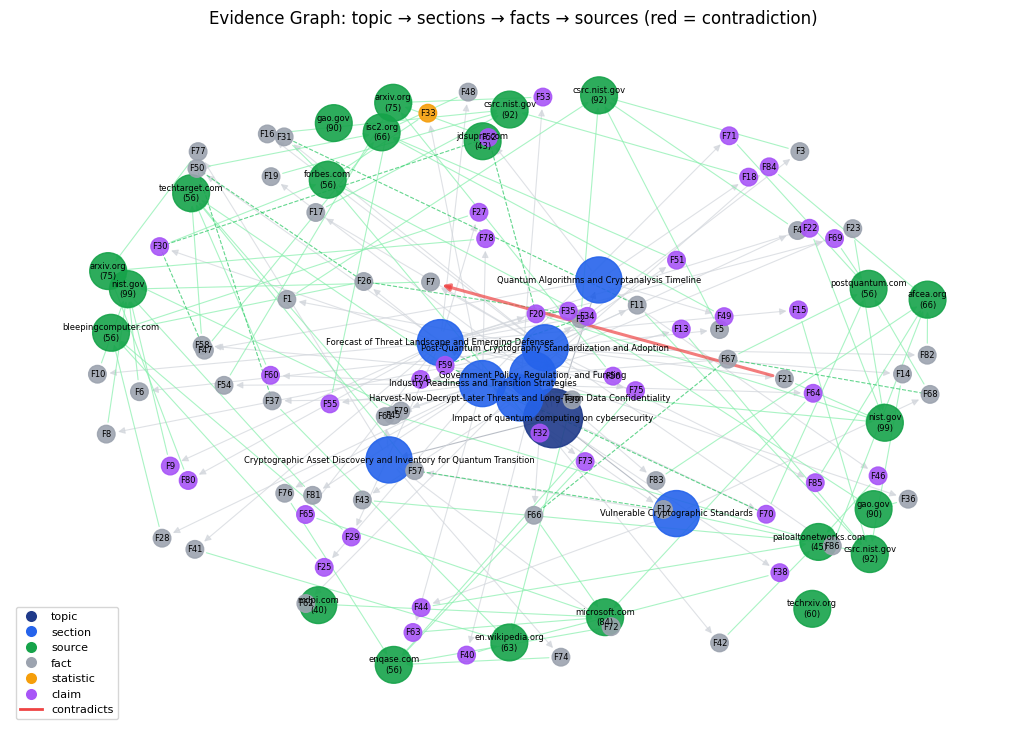

In [8]:
import matplotlib.pyplot as plt
fig = ra.draw_graph(session); plt.show()
import networkx as nx, json
json.dump(nx.node_link_data(session.graph), open("evidence_graph.json", "w"), default=str)

## Step 9 — Interactive research mode (no restart)

In [9]:
display(Markdown(agent.ask("Explain the impact on RSA encryption in more detail", session)))
display(Markdown(agent.expand_section("Post-Quantum", session)))   # deep-dive on a section (partial title match)

RSA encryption is vulnerable to quantum computers because a quantum algorithm can solve the mathematical problem on which RSA’s security relies.

* **Shor’s algorithm** – Developed by Peter Shor in 1994, this algorithm can factor large numbers on a theoretical quantum computer, directly threatening RSA encryption [F47].  

* **Timeline of the threat** – Experts believe that a quantum computer capable of breaking today’s public‑key schemes could appear within the next decade [F20], even though such machines do not yet exist [F9].  

* **Practical breaking estimates** – In 2019 Craig Gidney and Martin Ekerå estimated that a 2,048‑bit RSA key could be broken in about eight hours on a quantum machine with 20 million qubits; later methods might need fewer than a million qubits [F49].  

* **Policy and migration response** –  
  * NIST has already finalized a set of encryption algorithms designed to withstand quantum attacks, and these standards are ready for immediate use [F21].  
  * NIST’s draft guidance (IR 8547) recommends dropping quantum‑vulnerable algorithms such as RSA‑2048 after 2030 and plans to ban RSA entirely after 2035 [F57].  
  * U.S. federal agencies must adopt post‑quantum cryptography (PQC) for key establishment by the end of 2030 and transition digital signatures to PQC by the end of 2031 [F83].  

* **Technical mitigation** – Maintaining an inventory of cryptographic assets provides the visibility needed for “crypto‑agility,” allowing rapid updates when a vulnerability (such as a quantum break of RSA) is discovered [F64]. Combining crypto‑agility with hybrid encryption (using both classical and quantum‑resistant algorithms) is presented as an effective way to build quantum‑resilient systems [F55].

**In summary**, Shor’s algorithm gives quantum computers the ability to factor the large numbers that RSA relies on, and realistic estimates suggest that a sufficiently large quantum machine could break RSA‑2048 within hours. Experts expect such machines could exist within ten years, prompting immediate planning and migration to quantum‑resistant standards, inventory‑driven crypto‑agility, and hybrid approaches to protect data that currently relies on RSA.

Section 'Post-Quantum' not found. Sections: ['Quantum Algorithms and Cryptanalysis Timeline', 'Vulnerable Cryptographic Standards', 'Post‑Quantum Cryptography Standardization and Adoption', 'Industry Readiness and Transition Strategies', 'Government Policy, Regulation, and Funding', 'Forecast of Threat Landscape and Emerging Defenses', 'Harvest‑Now‑Decrypt‑Later Threats and Long‑Term Data Confidentiality', 'Cryptographic Asset Discovery and Inventory for Quantum Transition']

## Step 10 — Research memory
Past investigations are stored in `research_memory.json`; related future queries reuse cached URLs/facts.

In [10]:
import json; print(json.dumps(agent.memory['investigations'], indent=1))

[
 {
  "query": "How will quantum computing impact cybersecurity over the next 10 years?",
  "date": "2026-11-16",
  "topic": "Impact of quantum computing on cybersecurity",
  "n_sources": 22,
  "n_facts": 86
 }
]


## Step 11 — Streamlit app (same `research_agent.py`)

In [14]:
%%writefile app.py
import os
import streamlit as st
import research_agent as ra

st.set_page_config(page_title="Autonomous Research Agent", page_icon="🔎", layout="wide")
st.title("🔎 Autonomous Research & Intelligence Agent")

with st.sidebar:
    st.header("Settings")
    # >>> GROQ API KEY goes here (or in env var GROQ_API_KEY / .streamlit/secrets.toml) <<<
    try:
        default_key = os.environ.get("GROQ_API_KEY") or st.secrets.get("GROQ_API_KEY", "")
    except Exception:
        default_key = os.environ.get("GROQ_API_KEY", "")
    key = st.text_input("Groq API key", value=default_key, type="password",
                        help="Free key: https://console.groq.com/keys")
    model = st.text_input("Model", value=ra.DEFAULT_MODEL)
    max_sources = st.slider("Max sources", 6, 30, 10)
    min_cred = st.slider("Min credibility to keep a source", 0, 80, 40)
    n_contra = st.slider("Contradictions to investigate", 0, 5, 2)
    expand = st.checkbox("Dynamic research expansion", True)
    fast = st.checkbox("Use small model for extraction (saves quota)", False,
                       help="Uses llama-3.1-8b-instant for bulk extraction; separate Groq quota, slightly lower extraction quality")

query = st.text_area("Research question", "How will quantum computing impact cybersecurity over the next 10 years?")
run = st.button("Run research", type="primary", disabled=not (key and query))

if run:
    status = st.status("Researching...", expanded=True)
    try:
        agent = ra.ResearchAgent(llm=ra.LLM(api_key=key, model=model), max_sources=max_sources,
                                 min_credibility=min_cred, max_contradictions=n_contra, expand_topics=expand,
                                 fast_model="llama-3.1-8b-instant" if fast else None,
                                 log_fn=lambda m: status.write(m))
        st.session_state["agent"] = agent
        st.session_state["session"] = agent.run(query)
        st.session_state["chat"] = []
        status.update(label="Done", state="complete")
    except Exception as e:
        status.update(label="Failed", state="error")
        st.error(str(e))

s = st.session_state.get("session")
if s:
    agent = st.session_state["agent"]
    tabs = st.tabs(["📄 Report", "⚖️ Contradictions", "🕸️ Evidence graph", "📚 Sources", "🧩 Plan", "💬 Interactive"])
    with tabs[0]:
        st.markdown(s.report)
        st.download_button("Download report (.md)", s.report, file_name="research_report.md")
    with tabs[1]:
        df = ra.contradiction_table(s)
        if df.empty:
            st.info("No material contradictions detected.")
        else:
            st.dataframe(df, use_container_width=True)
            for c in s.contradictions:
                st.subheader(c.get("topic"))
                a, b = st.columns(2)
                a.metric("Claim A support", c["support_a"]); a.write(c["claim_a"]["text"])
                b.metric("Claim B support", c["support_b"]); b.write(c["claim_b"]["text"])
                st.success(f"Resolution ({c['verdict']}, {c['confidence']}% confidence): {c['resolution']}")
    with tabs[2]:
        st.pyplot(ra.draw_graph(s))
    with tabs[3]:
        st.dataframe(ra.sources_table(s), use_container_width=True)
    with tabs[4]:
        st.json({"understanding": s.understanding, "plan": s.plan})
    with tabs[5]:
        st.caption("Ask follow-ups or 'expand: <section name>' — no need to restart the research.")
        for role, msg in st.session_state.get("chat", []):
            st.chat_message(role).markdown(msg)
        q = st.chat_input("e.g. Explain the RSA section further")
        if q:
            st.chat_message("user").markdown(q)
            with st.spinner("Thinking..."):
                ans = agent.expand_section(q.split(":", 1)[1].strip(), s) if q.lower().startswith("expand:") else agent.ask(q, s)
            st.chat_message("assistant").markdown(ans)
            st.session_state["chat"] += [("user", q), ("assistant", ans)]

Overwriting app.py


In [12]:
# 1) stop anything left over from the localtunnel attempt
!pkill -f streamlit
!pkill -f localtunnel

# 2) get cloudflared (free tunnel, no signup)
!wget -q https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64 -O cloudflared
!chmod +x cloudflared

# 3) start Streamlit
import subprocess, time, re
subprocess.Popen(["streamlit", "run", "app.py",
                  "--server.port", "8501", "--server.headless", "true",
                  "--server.enableCORS", "false", "--server.enableXsrfProtection", "false"])
time.sleep(8)

# 4) open the tunnel and print the public link
log = open("cf.log", "w")
subprocess.Popen(["./cloudflared", "tunnel", "--url", "http://localhost:8501"], stderr=log, stdout=log)
url = None
for _ in range(30):
    time.sleep(1)
    m = re.search(r"https://[a-z0-9-]+\.trycloudflare\.com", open("cf.log").read())
    if m:
        url = m.group(0)
        break
print("Open this link:", url if url else "not found, run: !cat cf.log")

Open this link: https://necessity-statistics-possess-conversation.trycloudflare.com


In [13]:
print("Agent exists:", "agent" in globals())
print("Session exists:", "session" in globals())

if "session" in globals():
    print("Session type:", type(session))

Agent exists: True
Session exists: True
Session type: <class 'research_agent.Session'>


**Run locally instead:** `pip install groq ddgs trafilatura pypdf networkx matplotlib pandas streamlit`, put `research_agent.py` + `app.py` in one folder, set `GROQ_API_KEY`, run `streamlit run app.py`.